# Diamond_Data Analysis_Project

## Libraries section

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import figure
from pip._internal.models import index

## Data Extraction

In [2]:
list(sns.get_dataset_names())
df = sns.load_dataset("diamonds")
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [25]:
# df.to_excel("diamonds.xlsx")

## EDA : Understanding the Dataset

### First Step :  Data Understanding

In [3]:
df.shape

(53940, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [6]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [12]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

### Second Step :  Numerical Features (carat, depth, table, price, x, y, z)

In [21]:
# carat  depth  table  price  x  y  z

columns = ["carat", "depth", "table", "price", "x", "y", "z"]

for column in columns:
    print(column,": max=", df[column].max(),"      min=",df[column].min())
    print(df.loc[df[column] == df[column].max()])
    print(df.loc[df[column] ==df[column].min()])


carat :max= 5.01       min= 0.2
       carat   cut color clarity  depth  table  price      x      y     z
27415   5.01  Fair     J      I1   65.5   59.0  18018  10.74  10.54  6.98
       carat        cut color clarity  depth  table  price     x     y     z
14       0.2    Premium     E     SI2   60.2   62.0    345  3.79  3.75  2.27
31591    0.2    Premium     E     VS2   59.8   62.0    367  3.79  3.77  2.26
31592    0.2    Premium     E     VS2   59.0   60.0    367  3.81  3.78  2.24
31593    0.2    Premium     E     VS2   61.1   59.0    367  3.81  3.78  2.32
31594    0.2    Premium     E     VS2   59.7   62.0    367  3.84  3.80  2.28
31595    0.2      Ideal     E     VS2   59.7   55.0    367  3.86  3.84  2.30
31596    0.2    Premium     F     VS2   62.6   59.0    367  3.73  3.71  2.33
31597    0.2      Ideal     D     VS2   61.5   57.0    367  3.81  3.77  2.33
31598    0.2  Very Good     E     VS2   63.4   59.0    367  3.74  3.71  2.36
31599    0.2      Ideal     E     VS2   62.2   57.

### Third Step : Categorical Features (cut, color, clarity)

In [24]:
# cut, color, clarity

columns = ["cut", "color", "clarity"]

for column in columns:
    print(df[column].value_counts())


cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64
color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64
clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64


## Data Cleaning

###  Handling Duplicates

In [26]:
df.duplicated().sum()                      # Check duplicated samples !

np.int64(146)

In [27]:
df[df.duplicated()]                       # Observe duplicated samples!

,carat,cut,color,clarity,depth,table,price,x,y,z
1005,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1006,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1007,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
1008,0.79,Ideal,G,SI1,62.3,57.0,2898,5.90,5.85,3.66
2025,1.52,Good,E,I1,57.3,58.0,3105,7.53,7.42,4.28
...,...,...,...,...,...,...,...,...,...,...
47969,0.52,Ideal,D,VS2,61.8,55.0,1919,5.19,5.16,3.20
49326,0.51,Ideal,F,VVS2,61.2,56.0,2093,5.17,5.19,3.17
49557,0.71,Good,F,SI2,64.1,60.0,2130,0.00,0.00,0.00
50079,0.51,Ideal,F,VVS2,61.2,56.0,2203,5.19,5.17,3.17


Duplicate Records

As observed, this dataset contains 146 duplicated rows. However, since there is no unique identifier (ID) column to distinguish individual diamonds, we cannot determine with certainty whether these records represent duplicate entries or different diamonds with identical characteristics. Therefore, we will retain these records in the dataset for further analysis.

### Handling Missing Values

In [28]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Missing Values

As observed, there are no missing values in any of the columns

### Optimizing Data Types

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [30]:
df["price"] = df["price"].astype(np.uint16)        # Max Price = 18823

In [35]:
df[["carat","depth", "table", "x", "y", "z"]] = df[["carat","depth", "table", "x", "y", "z"]].astype(np.float16)


In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float16 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float16 
 5   table    53940 non-null  float16 
 6   price    53940 non-null  uint16  
 7   x        53940 non-null  float16 
 8   y        53940 non-null  float16 
 9   z        53940 non-null  float16 
dtypes: category(3), float16(6), uint16(1)
memory usage: 896.5 KB


## Visualization

### Data Analysis Targets

1. Does diamond price increase with carat weight?

2. Which clarity grade is the most common among diamonds?

3. Does cut quality affect diamond prices?

4. What is the percentage distribution of diamonds across different color grades?

5. Are diamonds with higher clarity grades more expensive?

6. How is the distribution of diamond prices across different clarity grades?


#### Does diamond price increase with carat weight?

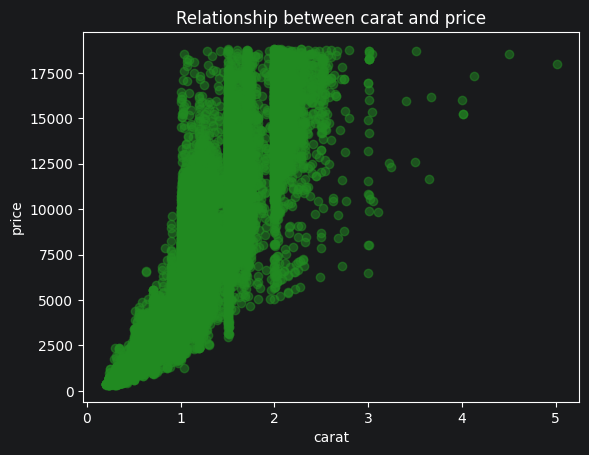

In [38]:
plt.scatter(df["carat"], df["price"], color="forestgreen", alpha=0.5)

plt.title("Relationship between carat and price")

plt.xlabel("carat")
plt.ylabel("price")

plt.show()

####  Which clarity grade is the most common among diamonds?

In [40]:
clarity_counts = df["clarity"].value_counts()
clarity_counts

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

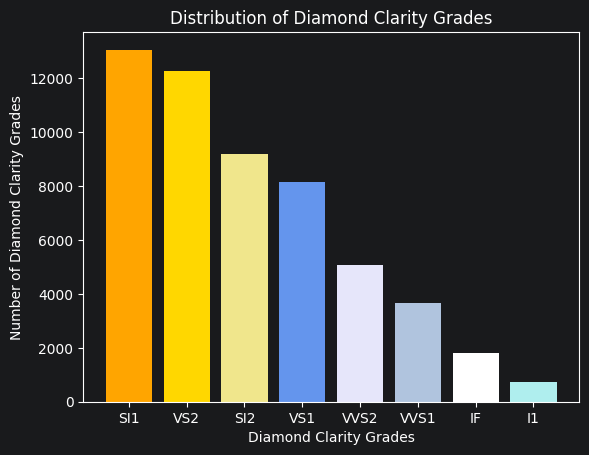

In [42]:
clarity_group = list(clarity_counts.index)

plt.bar(clarity_group, clarity_counts, color = ["orange", "gold","khaki","cornflowerblue",
                                                "lavender","lightsteelblue","w","paleturquoise"])
plt.title("Distribution of Diamond Clarity Grades")

plt.xlabel("Diamond Clarity Grades")
plt.ylabel("Number of Diamond Clarity Grades")

plt.show()

Result

As shown in the chart, SI1 (Slightly Included 1) is the most common clarity grade among the diamonds in this dataset.

#### Does cut quality affect diamond prices?

In [54]:
same_carat_diamonds_df = df.loc[(df["carat"]>=1) & (df["carat"]<=1.05)]
same_carat_diamonds_counts = same_carat_diamonds_df["cut"].value_counts()
same_carat_diamonds_counts

cut
Premium      1768
Very Good    1537
Ideal        1465
Good          913
Fair          359
Name: count, dtype: int64

In [71]:
cut_group =  ["Premium", "Ideal", "Very Good", "Good", "Fair"]

premium_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["cut"]=="Premium")]).mean()
ideal_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["cut"]=="Ideal")]).mean()
v_good_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["cut"]=="Very Good")]).mean()
good_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["cut"]=="Good")]).mean()
fair_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["cut"]=="Fair")]).mean()

premium_mean = round(premium_mean,2)
ideal_mean = round(ideal_mean,2)
v_good_mean = round(v_good_mean,2)
good_mean = round(good_mean,2)
fair_mean = round(fair_mean,2)

price_mean = [premium_mean, ideal_mean, v_good_mean, good_mean, fair_mean]



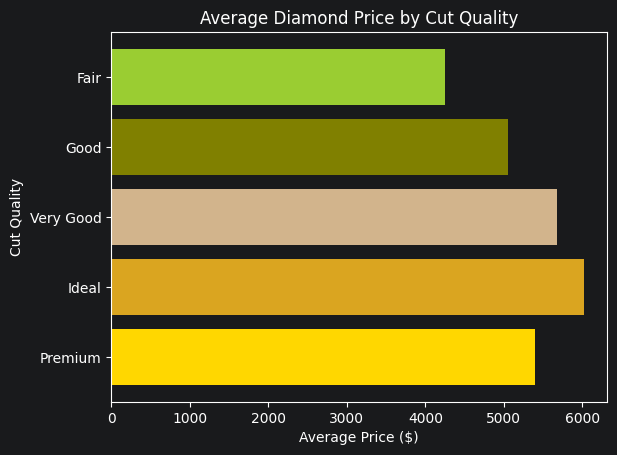

[np.float64(5396.55),
 np.float64(6013.26),
 np.float64(5672.68),
 np.float64(5049.44),
 np.float64(4244.72)]

In [73]:
plt.barh(cut_group,price_mean,color=["gold",
                                                                                    "goldenrod",
                                                                                    "tan",
                                                                                    "olive",
                                                                                    "yellowgreen"])
plt.xlabel("Average Price ($)")
plt.ylabel("Cut Quality")
plt.title("Average Diamond Price by Cut Quality")
plt.show()

price_mean

#### What is the percentage distribution of diamonds across different color grades?

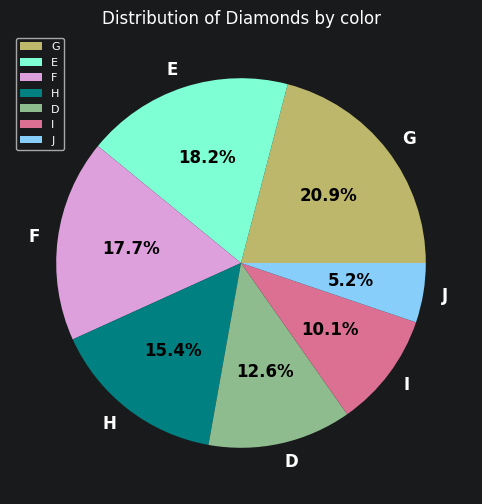

In [84]:
plt.figure(figsize=(12,6))
color_counts = df["color"].value_counts()
color_group = color_counts.index

a,b,c = plt.pie(color_counts,
        labels=color_group,
        autopct="%1.1f%%",
        colors = ["darkkhaki","aquamarine","plum","teal","darkseagreen","palevioletred","lightskyblue"],
        textprops= {"fontsize": 12, "fontweight": "bold"})

for x in c:
    x.set_color("black")

plt.title("Distribution of Diamonds by color")
plt.legend(loc="upper left", fontsize=8)
plt.show()


#### Are diamonds with higher clarity grades more expensive?

In [85]:
same_carat_diamonds_by_clarity_counts = same_carat_diamonds_df["clarity"].value_counts()
same_carat_diamonds_by_clarity_counts

clarity
SI1     1753
SI2     1595
VS2     1260
VS1      685
VVS2     387
VVS1     140
I1       126
IF        96
Name: count, dtype: int64

In [94]:
# IF → VVS1 → VVS2 → VS1 → VS2 → SI1 → SI2 → I1    BEST -------> WORST

clarity_group = ["IF", "VVS1", "VVS2", "VS1","VS2", "SI1", "SI2", "I1"]

SI1_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="SI1")]).mean()
SI2_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="SI2")]).mean()
VS2_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="VS2")]).mean()
VS1_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="VS1")]).mean()
VVS2_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="VVS2")]).mean()
VVS1_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="VVS1")]).mean()
I1_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="I1")]).mean()
IF_mean = (same_carat_diamonds_df["price"].loc[(same_carat_diamonds_df["clarity"]=="IF")]).mean()

SI1_mean = round(SI1_mean,2)
SI2_mean = round(SI2_mean,2)
VS2_mean = round(VS2_mean,2)
VS1_mean = round(VS1_mean,2)
VVS2_mean = round(VVS2_mean,2)
VVS1_mean = round(VVS1_mean,2)
I1_mean = round(I1_mean,2)
IF_mean = round(IF_mean,2)

price_mean_by_clarity = [IF_mean, VVS1_mean, VVS2_mean, VS1_mean,VS2_mean, SI1_mean, SI2_mean, I1_mean]


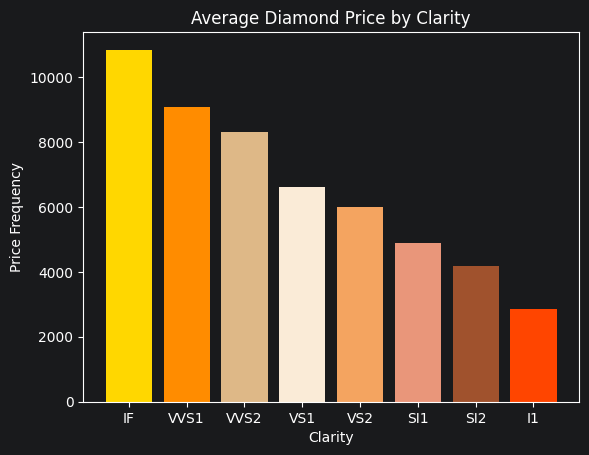

In [120]:
plt.bar(clarity_group,price_mean_by_clarity,color=["gold","darkorange", "burlywood",
                                                   "antiquewhite","sandybrown","darksalmon",
                                                   "sienna","orangered"])
plt.xlabel("Clarity")
plt.ylabel("Price Frequency")

plt.title("Average Diamond Price by Clarity")
plt.show()

#### How is the distribution of diamond prices across different clarity grades?

In [97]:
clarity_category = df["clarity"].value_counts()
clarity_category

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64

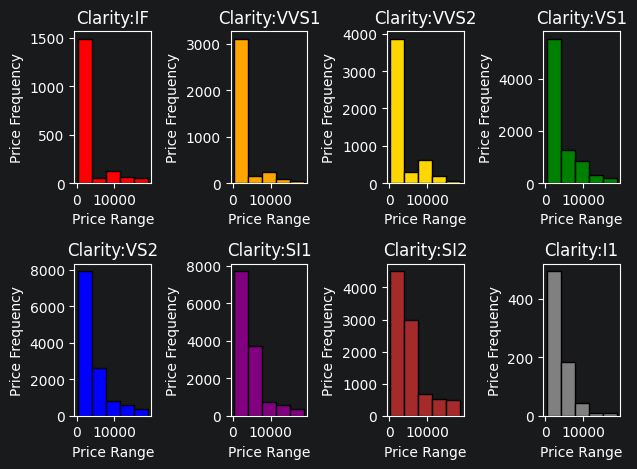

In [119]:
# IF → VVS1 → VVS2 → VS1 → VS2 → SI1 → SI2 → I1    BEST -------> WORST
x = np.linspace(df["price"].min(), df["price"].max(),6)
clarity_group = ["IF", "VVS1", "VVS2", "VS1","VS2", "SI1", "SI2", "I1"]
colors = ["r", "orange", "gold", "g",
          "b", "purple", "brown", "gray"]

for index, column in enumerate(clarity_group):
    plt.subplot(2,4,index+1)
    plt.hist(df["price"].loc[df["clarity"]==column], bins = x ,color = colors[index],edgecolor="black")

    plt.xlabel("Price Range")
    plt.ylabel(f"Price Frequency")
    plt.title(f"Clarity:{column}")

plt.tight_layout()
plt.show()


